# Finger-Video rPPG Analysis

Converted from a MATLAB pipeline (`ExtractVideo.m`, `Finger_Pulse_Code.m`, `siv_*.m`) into Python.

**Pipeline:**
1. Read a finger-on-camera video
2. Extract a remote-PPG (rPPG) signal from frame intensity and preprocess it
3. Plot the rPPG signal with detected pulse peaks
4. Estimate Pulse Rate (PR) via three independent methods (count-based, PPI-based, AMDF-based) and fuse them, plus Signal Quality Assessment (SQA) and rhythm regularity
5. Estimate SpO2 and Perfusion Index (PI) — **new**, not in the original MATLAB code
6. Estimate Respiratory Rate (RR) from pulse-interval frequency modulation — **new**, not in the original MATLAB code

> **Important caveat:** SpO2 here is estimated from a standard RGB camera (Red/Blue channel ratio-of-ratios) using generic calibration constants, not a clinically calibrated red/infrared pulse oximeter signal. Treat SpO2/PI/RR outputs as experimental / research-grade, not medical-grade measurements.

## 0. Setup

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import filtfilt, cheby1, butter, welch

%matplotlib inline

## 1. Configuration

Set the path to your finger-video file and the analysis parameters below.
`DISCARD_SEC` trims unstable seconds at the start/end of the recording (as in the original script), and `DURATION_SEC` is how much signal (after trimming) to analyze.

In [2]:
VIDEO_PATH = "Asit_1.mp4"   # <-- change this to your video file path

DISCARD_SEC   = 5     # seconds trimmed from the start AND the end of the video
DURATION_SEC  = 60    # seconds of signal to analyze after trimming
RESIZE_FACTOR = 0.1   # spatial downsample factor applied to each frame before averaging

## 2. Read the video

Equivalent of `ExtractVideo.m`. Reads every frame with OpenCV and reports frame rate, dimensions and frame count.

In [3]:
def extract_video(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise IOError(f"Could not open video file: {path}")
    fps = cap.get(cv2.CAP_PROP_FPS)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frames = []
    while True:
        ret, frame = cap.read()   # frame is BGR (OpenCV convention)
        if not ret:
            break
        frames.append(frame)
        if len(frames) % 100 == 0:
            print(f"Reading frame: {len(frames)}")
    cap.release()
    return frames, fps, h, w

frames, fps, h, w = extract_video(VIDEO_PATH)
fps = round(fps)
print(f"\nLoaded {len(frames)} frames | {w}x{h} | {fps} fps | duration ~{len(frames)/fps:.1f}s")

Reading frame: 100
Reading frame: 200
Reading frame: 300
Reading frame: 400
Reading frame: 500
Reading frame: 600
Reading frame: 700
Reading frame: 800
Reading frame: 900
Reading frame: 1000
Reading frame: 1100
Reading frame: 1200
Reading frame: 1300
Reading frame: 1400
Reading frame: 1500
Reading frame: 1600
Reading frame: 1700
Reading frame: 1800
Reading frame: 1900
Reading frame: 2000
Reading frame: 2100

Loaded 2132 frames | 478x850 | 30 fps | duration ~71.1s


In [4]:
# Discard the first/last DISCARD_SEC seconds, keep DURATION_SEC seconds of signal
C1 = DISCARD_SEC * fps
n_needed = DURATION_SEC * fps

if C1 + n_needed > len(frames):
    raise ValueError(
        f"Video too short: need {DISCARD_SEC*2 + DURATION_SEC}s of footage, "
        f"have {len(frames)/fps:.1f}s. Reduce DURATION_SEC/DISCARD_SEC or use a longer video."
    )

frames = frames[C1: C1 + n_needed]
n_frames = len(frames)
print(f"Using {n_frames} frames ({n_frames/fps:.1f}s) for analysis")

Using 1800 frames (60.0s) for analysis


## 3. Extract the raw rPPG signal

Equivalent of the frame-processing loop in `Finger_Pulse_Code.m`. Each frame is spatially downsampled, and we compute:
- `d_gray`: summed grayscale intensity per frame (the original MATLAB signal used for PR/rhythm)
- `d_R`, `d_G`, `d_B`: mean per-channel intensity per frame (used later for SpO2/PI)

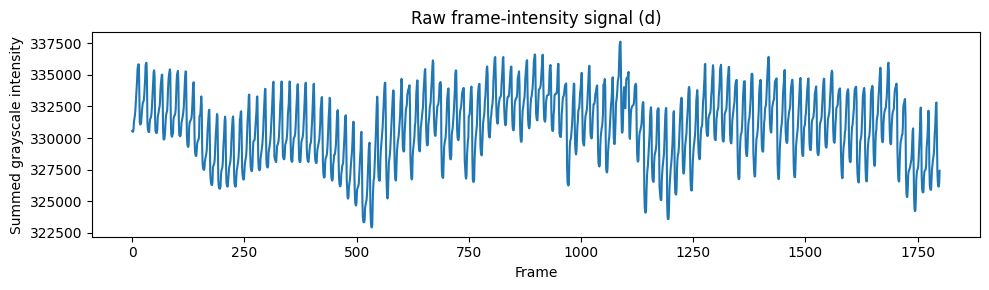

In [5]:
d_gray = np.zeros(n_frames)
d_R = np.zeros(n_frames)
d_G = np.zeros(n_frames)
d_B = np.zeros(n_frames)

for i, fr in enumerate(frames):
    small = cv2.resize(fr, None, fx=RESIZE_FACTOR, fy=RESIZE_FACTOR, interpolation=cv2.INTER_AREA)
    b_ch = small[:, :, 0].astype(np.float64)
    g_ch = small[:, :, 1].astype(np.float64)
    r_ch = small[:, :, 2].astype(np.float64)
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY).astype(np.float64)

    d_gray[i] = np.sum(gray)          # matches MATLAB's 'Averaging Entire Image for Intensity'
    d_R[i] = np.mean(r_ch)
    d_G[i] = np.mean(g_ch)
    d_B[i] = np.mean(b_ch)

t1 = n_frames / fps   # signal duration in seconds

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(d_gray, color='tab:blue')
ax.set_title("Raw frame-intensity signal (d)")
ax.set_xlabel("Frame"); ax.set_ylabel("Summed grayscale intensity")
plt.tight_layout(); plt.show()

## 4. Preprocess the rPPG signal

Detrend (remove mean), normalize, and apply a high-pass Chebyshev filter to remove baseline wander — matches the `d -> d_m -> d_a -> cheby1 high-pass -> x` chain in `Finger_Pulse_Code.m`.

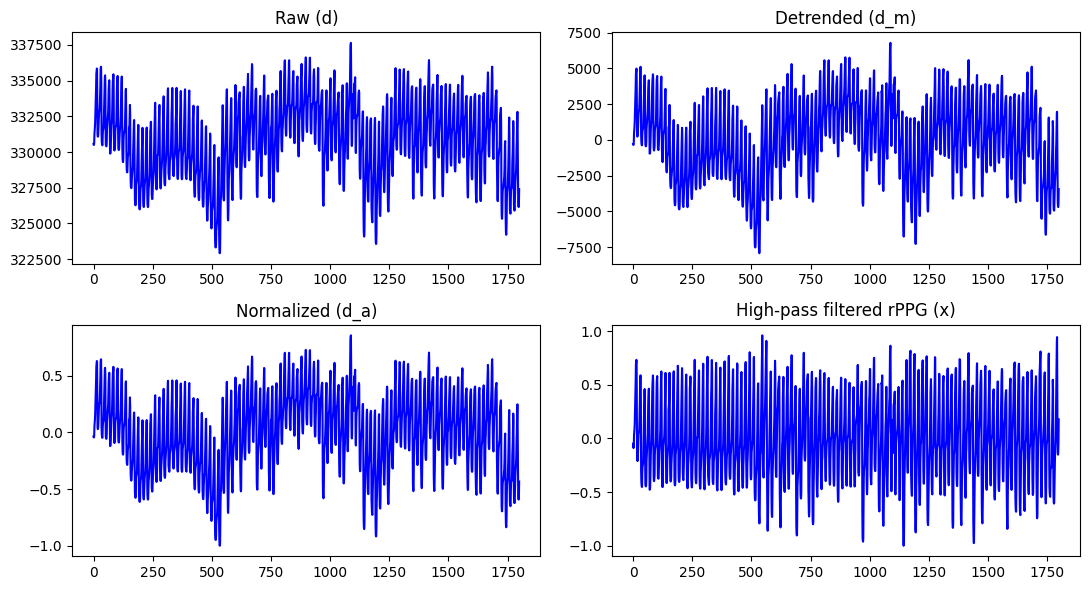

In [6]:
d = d_gray
d_m = d - np.mean(d)
d_a = d_m / np.max(np.abs(d_m))

b0, a0 = cheby1(5, 0.001, 0.5 / (fps / 2), btype='high')
x = filtfilt(b0, a0, d_a)
x = x / np.max(np.abs(x))   # final preprocessed rPPG signal

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0,0].plot(d, 'b'); axes[0,0].set_title('Raw (d)')
axes[0,1].plot(d_m, 'b'); axes[0,1].set_title('Detrended (d_m)')
axes[1,0].plot(d_a, 'b'); axes[1,0].set_title('Normalized (d_a)')
axes[1,1].plot(x, 'b'); axes[1,1].set_title('High-pass filtered rPPG (x)')
plt.tight_layout(); plt.show()

## 5. Core signal-processing functions

Direct translations of the `siv_*.m` helper functions.

In [7]:
def moving_avg_fil(x, N):
    """siv_moving_avg_fil.m — zero-phase moving-average (box) filter."""
    N = int(N)
    b = np.ones(N) / N
    a = [1.0]
    padlen = 3 * (max(len(a), len(b)) - 1)
    if len(x) <= padlen:
        return filtfilt(b, a, x, padlen=max(0, len(x) - 2))
    return filtfilt(b, a, x)


def th_cross(x, m='b', th=0.0):
    """siv_th_cross.m — generic threshold crossing. m: 'p'=positive-going, 'n'=negative-going, 'b'=both."""
    x = np.asarray(x)
    s = (x >= th).astype(int)
    k = s[1:] - s[:-1]
    if 'p' in m:
        f = np.where(k > 0)[0]
    elif 'n' in m:
        f = np.where(k < 0)[0]
    else:
        f = np.where(k != 0)[0]
    return f


def neg_th_cross(ydif, th):
    """siv_neg_th_cross.m — negative-going threshold crossing with 1-sample refinement (used to locate peaks)."""
    ydif = np.asarray(ydif)
    L = len(ydif)
    out = []
    i = 0
    while i < L - 3:
        if ydif[i] > th and ydif[i + 1] <= th:
            if abs(ydif[i + 1]) > abs(ydif[i + 2]):
                out.append(i + 2)
            else:
                out.append(i + 1)
        i += 1
    return np.array(out, dtype=int)


def peakanno_amdf(ym):
    """siv_peakanno_AMDF.m — locate the first prominent peak of ym (called with ym = -AMDF)."""
    ym = np.asarray(ym, dtype=float)
    ydif = np.gradient(ym)
    ydif = moving_avg_fil(ydif, 3)
    if len(ydif) >= 10:
        ydif[0:10] = ydif[9]
    mx = np.max(np.abs(ydif))
    if mx == 0:
        mx = 1.0
    ydif = ydif / mx
    zerocross = neg_th_cross(ydif, -0.1)
    if len(zerocross) < 2:
        zerocross = np.array([0, 0])  # fallback for the (rare) no-peak edge case
    return zerocross


def amdf(x, max_lag=None):
    """siv_AMDF_04.m — Average Magnitude Difference Function (vectorized). D[i] corresponds to lag (i+1)."""
    x = np.asarray(x, dtype=float)
    N = len(x)
    if max_lag is None:
        max_lag = N - 1
    max_lag = min(max_lag, N - 1)
    D = np.zeros(max_lag)
    for k in range(1, max_lag + 1):
        D[k - 1] = np.mean(np.abs(x[:N - k] - x[k:N]))
    return D


def sqa(x, AMDF, locs2, PR):
    """siv_SQA.m — signal-quality assessment. Returns 0 = good, 1 = bad."""
    th, thm = 0.1, -0.1
    cross_th_o = th_cross(x, 'b', th)
    cross_thm_o = th_cross(x, 'b', thm)

    N = len(locs2)
    if locs2[0] == 0 or (len(locs2) > 1 and locs2[1] == 0):
        N = 0

    mag = abs(len(cross_th_o) - len(cross_thm_o))

    if N < 2 or PR < 30 or PR > 300:
        return 1
    elif (AMDF[locs2[0]] > -0.25 and AMDF[locs2[1]] > -0.25) and mag > 5:
        return 1
    elif (AMDF[locs2[0]] < -0.5 and AMDF[locs2[1]] < -0.5) and mag <= 5:
        return 0
    else:
        rng = np.concatenate(([0], locs2))
        distance = np.diff(rng)
        dist = np.diff(distance)
        SQ = 0
        for k in dist:
            SQ = 1 if k > 5 else 0
            if SQ == 1:
                break
        return SQ


def amdf_pr_sqa(x, Fs):
    """siv_AMDF_PR_SQA.m — pulse rate + SQA from the AMDF's first minimum."""
    AMDF_h = int(round(2 * (60 * Fs) / 30))  # max lag considered (~15 bpm floor)
    AMDFo = amdf(x, max_lag=AMDF_h)
    A = AMDFo[:AMDF_h].copy()
    A = A - np.mean(A)
    famp = np.max(np.abs(A))
    if famp == 0:
        famp = 1.0
    A = A / famp

    locs2 = peakanno_amdf(-A)
    if locs2[0] > 5 and locs2[0] <= AMDF_h - 5:
        lo, hi = locs2[0] - 5, locs2[0] + 6
        ref = np.argmin(A[lo:hi])
        locs2[0] = lo + ref

    lag = locs2[0] + 1  # array index -> lag in samples
    PR = int(np.floor(60 * Fs / lag)) if lag > 0 else 0

    SQ = sqa(x, A, locs2, PR)
    return PR, SQ, A, locs2


def ppg_spd(y, Fs, t):
    """siv_PPG_SPD.m — systolic-peak detection + count/PPI-based pulse rate."""
    order = max(int(np.ceil(0.1 * Fs)), 1)
    y = moving_avg_fil(y, order)
    x_d = np.gradient(y)
    x_d = moving_avg_fil(x_d, order)
    mx = np.max(np.abs(x_d))
    if mx == 0:
        mx = 1.0
    x_d = x_d / mx

    SP = neg_th_cross(x_d, 0.0)   # systolic peak sample indices
    PPI = np.diff(SP) / Fs        # pulse-to-pulse intervals (s)
    N = len(SP)
    PPI_avg = np.mean(PPI) if len(PPI) else np.nan
    PR1 = round(N * 60 / t)
    PR2 = round(60 / PPI_avg) if PPI_avg and not np.isnan(PPI_avg) else 0
    return PR1, PR2, SP, PPI, y, x_d


def rhythm(RRI):
    """siv_Rhythm.m — regular (1) / irregular (0) from pulse-interval variability."""
    RRI = np.asarray(RRI)
    if len(RRI) == 0:
        return 0
    RRI_avg = np.mean(RRI)
    RRI_deci = np.abs(RRI - RRI_avg) > 0.12
    return 0 if np.sum(RRI_deci) > 0 else 1


def rhythm_amdf(x, Fs, Ref_PR, n_segments=6, seg_seconds=10):
    """siv_Rhythm_AMDF.m — per-10s-segment AMDF pulse-rate check against a reference PR."""
    BL = int(seg_seconds * Fs)
    PR = np.zeros(n_segments)
    SQA_arr = np.zeros(n_segments)
    n_done = 0

    for i in range(n_segments):
        n1, ne = i * BL, i * BL + BL
        if ne > len(x):
            break
        x1 = x[n1:ne]
        n_done += 1

        A = amdf(x1)
        A = A - np.mean(A)
        famp = np.max(np.abs(A))
        if famp == 0:
            famp = 1.0
        A = A / famp

        locs2 = peakanno_amdf(-A)
        if locs2[0] > 5 and locs2[0] <= len(A) - 5:
            lo, hi = locs2[0] - 5, locs2[0] + 6
            ref = np.argmin(A[lo:hi])
            locs2[0] = lo + ref

        lag = locs2[0] + 1
        PR[i] = np.floor(60 * Fs / lag) if lag > 0 else 0
        SQA_arr[i] = sqa(x1, A, locs2, PR[i])

    PR, SQA_arr = PR[:n_done], SQA_arr[:n_done]
    PR0 = PR.copy()
    PR_good = PR[SQA_arr == 0]

    if len(PR_good) > 1:
        PR_deci = np.abs(PR_good - Ref_PR) > 5
        Rhythm_flag = 0 if np.sum(PR_deci) > 0 else 1
    else:
        print("Not enough good-quality segments to assess rhythm")
        Rhythm_flag = 0

    return Rhythm_flag, PR_good, PR0, SQA_arr

## 6. Pulse Rate + Signal Quality Assessment

Three independent PR estimates (as in `Finger_Pulse_Code.m`): count-based, PPI-based (both from `siv_PPG_SPD`), and AMDF-based (`siv_AMDF_PR_SQA`), followed by fusion.

In [8]:
PR1, PR2, SP, PPI, y_smooth, x_d = ppg_spd(x.copy(), fps, t1)
print(f"Pulse rate from Count-based Method: {PR1}")
print(f"Pulse rate from PPI-based Method:   {PR2}")

PR3, SQ, AMDF_arr, locs2 = amdf_pr_sqa(x.copy(), fps)
print(f"Pulse rate from AMDF-based Method:  {PR3}")
print("Signal Quality is", "Bad" if SQ == 1 else "Good")

Pulse rate from Count-based Method: 102
Pulse rate from PPI-based Method:   102
Pulse rate from AMDF-based Method:  100
Signal Quality is Good


In [9]:
# ---- Fusion (matches the MATLAB script's range/dist logic) ----
rng = [PR3, PR1, PR2, PR3]
dist = np.diff(rng)
dist1 = (dist > 10).astype(int)
val = int(np.sum(dist1))

fusion = None
if val == 0:
    fusion = round((PR1 + PR2 + PR3) / 3)
elif val == 2:
    fusion = round((PR1 + PR2 + PR3) / 3)
else:
    print("Signal Quality is Bad (fusion inconclusive)")

if fusion is not None:
    print(f"Fusion PR is {fusion} bpm")

Fusion PR is 101 bpm


## 7. Plot the rPPG signal with detected peaks

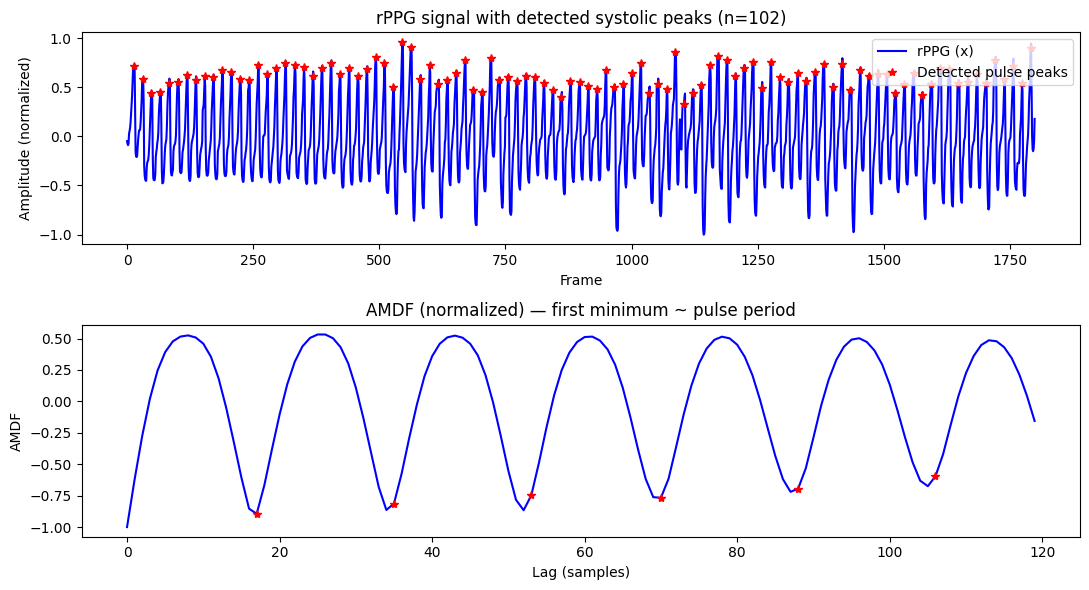

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=False)

axes[0].plot(x, 'b', label='rPPG (x)')
axes[0].plot(SP, x[SP], 'r*', label='Detected pulse peaks')
axes[0].set_title(f"rPPG signal with detected systolic peaks (n={len(SP)})")
axes[0].set_xlabel("Frame"); axes[0].set_ylabel("Amplitude (normalized)")
axes[0].legend(loc='upper right')

axes[1].plot(AMDF_arr, 'b')
if len(locs2) > 0:
    axes[1].plot(locs2, AMDF_arr[np.clip(locs2, 0, len(AMDF_arr)-1)], 'r*')
axes[1].set_title("AMDF (normalized) — first minimum ~ pulse period")
axes[1].set_xlabel("Lag (samples)"); axes[1].set_ylabel("AMDF")

plt.tight_layout(); plt.show()

## 8. Rhythm regularity

In [11]:
Rh = rhythm(PPI)
print("Rhythm is", "Regular" if Rh == 1 else "Irregular", "(using pulse-interval variability)")

ref_pr = fusion if fusion is not None else PR3
Rh_amdf, PR_good_segments, PR0_segments, SQA_segments = rhythm_amdf(x.copy(), fps, ref_pr)
print("Rhythm is", "Regular" if Rh_amdf == 1 else "Irregular", "(using per-segment AMDF)")
print("Per-segment PR (10s windows):", PR0_segments)
print("Per-segment signal quality (0=good,1=bad):", SQA_segments)

Rhythm is Regular (using pulse-interval variability)
Rhythm is Regular (using per-segment AMDF)
Per-segment PR (10s windows): [100. 100. 100. 105. 100. 100.]
Per-segment signal quality (0=good,1=bad): [0. 0. 0. 0. 0. 0.]


## 9. SpO2 and Perfusion Index (new)

Not present in the original MATLAB code. Estimated from the ratio-of-ratios of the AC/DC components of the Red and Blue channels (a common approach for standard RGB cameras, since there is no dedicated infrared channel). `PI` (Perfusion Index) is the AC/DC ratio of the red channel, expressed as a percentage — a common measure of pulsatile blood-volume strength.

**Calibration:** SpO2 is computed as `SpO2 = -1.1 * R + 98`, where `R` is the ratio-of-ratios of the AC/DC components of the Red and Blue channels. Replace the `-1.1`/`98` constants if you have your own calibration (e.g. against a reference pulse oximeter).

In [12]:
def bandpass(sig, fs, lo, hi, order=3):
    ny = fs / 2
    b, a = butter(order, [lo / ny, hi / ny], btype='band')
    return filtfilt(b, a, sig)

def ac_dc(channel_sig, fs, lo=0.7, hi=4.0):
    dc = np.mean(channel_sig)
    ac_sig = bandpass(channel_sig, fs, lo, hi)  # isolate the cardiac band (~42-240 bpm)
    ac = np.std(ac_sig)
    return ac, dc

AC_R, DC_R = ac_dc(d_R, fps)
AC_B, DC_B = ac_dc(d_B, fps)

R_ratio = (AC_R / DC_R) / (AC_B / DC_B)
SpO2 = float(np.clip(-1.1 * R_ratio + 98, 70, 100))   # SpO2 = -1.1*R + 98
PI = (AC_R / DC_R) * 100

print(f"Estimated SpO2: {SpO2:.1f} %  (approximate, RGB-camera based)")
print(f"Perfusion Index (PI): {PI:.2f} %")

Estimated SpO2: 98.0 %  (approximate, RGB-camera based)
Perfusion Index (PI): 0.55 %


## 10. Respiratory Rate (new)

Not present in the original MATLAB code. Estimated via **respiratory frequency modulation** of the pulse: the amplitude of each detected systolic peak is resampled onto a uniform time grid, detrended, band-pass filtered to the respiratory band, and the dominant frequency (via a zero-padded FFT for finer resolution than a short Welch window gives) gives the RR.

**Note:** the band's lower edge is set to 0.15 Hz (9 breaths/min) rather than 0.1 Hz (6 breaths/min). The old, wider band could pick up slow drift (finger pressure changes, lighting shifts) at the very bottom edge and misreport it as an implausibly slow breathing rate — which is what produced an incorrect low value like 8 breaths/min instead of the true rate. Excluding that near-drift region and adding an explicit linear detrend forces the peak search onto genuine respiratory-band content.

In [13]:
from scipy.signal import detrend

def estimate_rr(SP_idx, fs, y_signal):
    if len(SP_idx) < 4:
        return np.nan
    peak_times = SP_idx / fs
    peak_amps = y_signal[SP_idx]

    fs_u = 4.0  # uniform resample rate for the amplitude-envelope series
    t_uniform = np.arange(peak_times[0], peak_times[-1], 1 / fs_u)
    if len(t_uniform) < 16:
        return np.nan
    amp_interp = np.interp(t_uniform, peak_times, peak_amps)
    amp_interp = detrend(amp_interp)   # remove slow drift before filtering/peak-picking

    ny = fs_u / 2
    lo, hi = 0.15, min(0.7, ny * 0.95)   # 9-42 breaths/min (covers normal range through tachypnea)
    b, a = butter(3, [lo / ny, hi / ny], btype='band')
    resp = filtfilt(b, a, amp_interp)

    nfft = 4096  # zero-pad for finer frequency resolution than a short window would give
    freqs = np.fft.rfftfreq(nfft, d=1 / fs_u)
    spectrum = np.abs(np.fft.rfft(resp, n=nfft)) ** 2
    band = (freqs >= lo) & (freqs <= hi)
    if not np.any(band):
        return np.nan
    peak_f = freqs[band][np.argmax(spectrum[band])]
    return peak_f * 60

RR = estimate_rr(SP, fps, y_smooth)
print(f"Estimated Respiratory Rate: {RR:.1f} breaths/min" if not np.isnan(RR) else "RR: not enough peaks to estimate")

Estimated Respiratory Rate: 23.4 breaths/min


## 11. Summary

In [14]:
print("===== rPPG Analysis Summary =====")
print(f"Video duration analyzed : {t1:.1f} s  |  fps: {fps}")
print(f"Pulse Rate (count-based): {PR1} bpm")
print(f"Pulse Rate (PPI-based)  : {PR2} bpm")
print(f"Pulse Rate (AMDF-based) : {PR3} bpm  | Signal Quality: {'Bad' if SQ==1 else 'Good'}")
print(f"Fusion Pulse Rate       : {fusion if fusion is not None else 'N/A (bad quality)'} bpm")
print(f"Rhythm (PPI method)     : {'Regular' if Rh==1 else 'Irregular'}")
print(f"Rhythm (AMDF method)    : {'Regular' if Rh_amdf==1 else 'Irregular'}")
print(f"SpO2 (approx.)          : {SpO2:.1f} %")
print(f"Perfusion Index (PI)    : {PI:.2f} %")
print(f"Respiratory Rate        : {RR:.1f} breaths/min" if not np.isnan(RR) else "Respiratory Rate        : N/A")

===== rPPG Analysis Summary =====
Video duration analyzed : 60.0 s  |  fps: 30
Pulse Rate (count-based): 102 bpm
Pulse Rate (PPI-based)  : 102 bpm
Pulse Rate (AMDF-based) : 100 bpm  | Signal Quality: Good
Fusion Pulse Rate       : 101 bpm
Rhythm (PPI method)     : Regular
Rhythm (AMDF method)    : Regular
SpO2 (approx.)          : 98.0 %
Perfusion Index (PI)    : 0.55 %
Respiratory Rate        : 23.4 breaths/min
